# 02 — Partie A : distribution des labels, classifieurs triviaux, baseline, raccourcis

### A.1 Distribution des labels
Pour chaque valeur : quel **pourcentage** des arguments l'ont à 1 ? Globalement, par split, et par position (pour / contre).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from valeval.data import load_split, VALUES

SPLITS = {"train": "training", "val": "validation", "test": "test"}
d = {nom: load_split(fichier) for nom, fichier in SPLITS.items()}

dist = pd.DataFrame({nom: df[VALUES].mean() * 100 for nom, df in d.items()}).round(1)
dist["n_train"] = d["train"][VALUES].sum()          # nombre d'exemples positifs pour l'entraînement
dist["test - val"] = (dist.test - dist.val).round(1)
dist = dist.sort_values("train", ascending=False)
dist

,train,val,test,n_train,test - val
Universalism: concern,38.6,36.2,37.3,2081,1.1
Security: personal,37.1,40.0,34.1,2000,-5.9
Security: societal,32.0,25.7,25.2,1728,-0.5
Achievement,28.0,30.3,26.1,1512,-4.2
Self-direction: action,25.9,26.2,24.8,1395,-1.4
Benevolence: caring,24.7,33.4,21.3,1332,-12.1
Conformity: rules,21.8,24.0,18.2,1177,-5.8
Universalism: objectivity,19.5,19.6,29.9,1054,10.3
Self-direction: thought,18.3,13.2,9.1,988,-4.1
Benevolence: dependability,14.9,14.1,10.3,806,-3.8


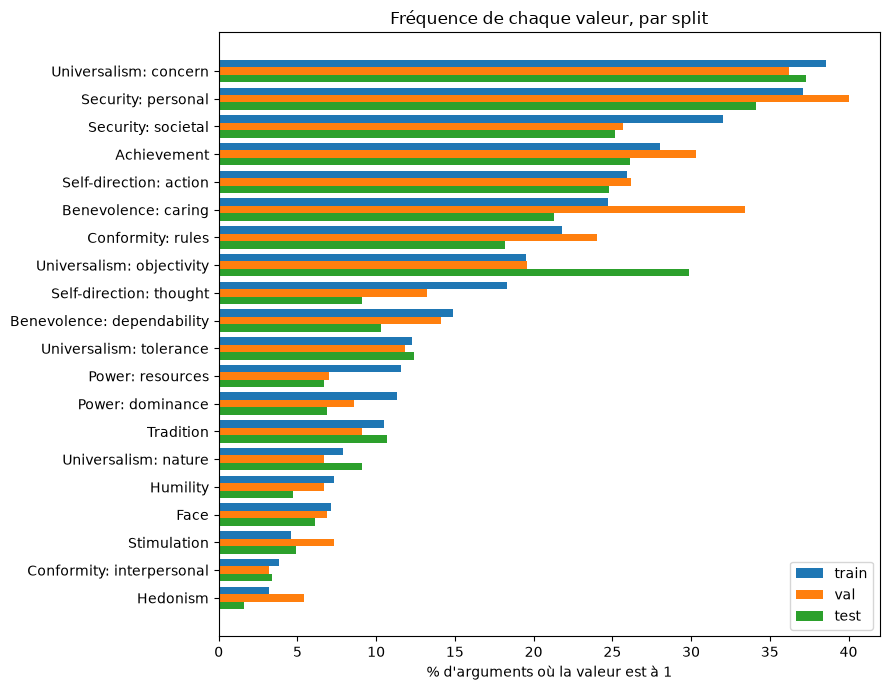

In [2]:
fig, ax = plt.subplots(figsize=(9, 7))
y = range(len(dist))
for i, nom in enumerate(["train", "val", "test"]):
    ax.barh([v + (i - 1) * .27 for v in y], dist[nom], height=.27, label=nom)
ax.set_yticks(list(y), dist.index); ax.invert_yaxis()
ax.set(xlabel="% d'arguments où la valeur est à 1", title="Fréquence de chaque valeur, par split")
ax.legend(); plt.tight_layout(); plt.savefig("../figures/A_distribution_valeurs.png", dpi=120); plt.show()

**Lecture :**
- **Fort déséquilibre** : *Universalism: concern* est présent dans ~38 % des arguments, *Hedonism* dans ~3 % (172 exemples seulement dans train). Les valeurs rares seront les plus dures à apprendre.
- **Décalage de prior valeur par valeur** : il n'est pas uniforme. *Universalism: objectivity* passe de 19,6 % (val) à **29,9 %** (test) ; *Benevolence: caring* de 33,4 % (val) à **21,3 %** (test). Un seuil réglé sur val sera trop strict pour la première et trop laxiste pour la seconde → à mesurer en F1 / Q10.

### Par position (pour / contre)

In [3]:
print("Part de chaque position :")
print(pd.DataFrame({nom: df.stance.value_counts(normalize=True).round(3) for nom, df in d.items()}))

pos = d["train"].groupby("stance")[VALUES].mean().T * 100
pos["écart (pour - contre)"] = pos["in favor of"] - pos["against"]
pos = pos.round(1).sort_values("écart (pour - contre)")
pos

Part de chaque position :
             train    val   test
stance                          
in favor of  0.537  0.558  0.551
against      0.463  0.442  0.449


stance,against,in favor of,écart (pour - contre)
Tradition,16.4,5.5,-10.9
Self-direction: action,29.4,22.8,-6.6
Hedonism,4.6,2.0,-2.6
Power: resources,12.8,10.6,-2.2
Achievement,29.2,27.0,-2.2
Power: dominance,12.4,10.4,-2.1
Face,7.9,6.4,-1.4
Stimulation,5.1,4.1,-0.9
Security: societal,32.2,31.9,-0.3
Humility,7.4,7.3,-0.1


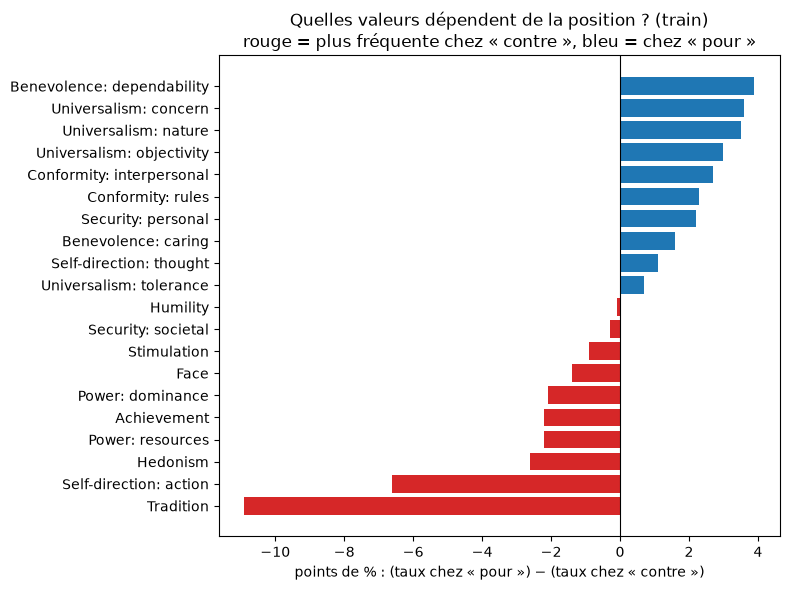

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ecart = pos["écart (pour - contre)"]
ax.barh(ecart.index, ecart, color=["tab:red" if e < 0 else "tab:blue" for e in ecart])
ax.axvline(0, color="black", lw=.8)
ax.set(xlabel="points de % : (taux chez « pour ») − (taux chez « contre »)",
       title="Quelles valeurs dépendent de la position ? (train)\nrouge = plus fréquente chez « contre », bleu = chez « pour »")
plt.tight_layout(); plt.savefig("../figures/A_valeurs_par_position.png", dpi=120); plt.show()

**Lecture :**
- Les positions sont équilibrées (~55 % pour / 45 % contre) dans les 3 splits.
- La plupart des valeurs sont aussi fréquentes chez « pour » que chez « contre », **sauf** :
  - **Tradition** : 16,4 % chez « contre » vs 5,5 % chez « pour » (×3). Les conclusions proposent presque toujours un **changement** (« We should ban / abolish / legalize… ») ; être *contre* un changement, c'est souvent défendre l'ordre établi → Tradition.
  - **Self-direction: action** : plus fréquente chez « contre ». S'opposer à « We should ban X », c'est souvent défendre la **liberté de choisir**.
- Conséquence : la position **pourrait** être utile à un modèle, d'où la consigne de la mettre en entrée. Son apport réel est mesuré par ablation en A.4.

### A.2 Classifieurs triviaux et choix de la métrique

Deux « modèles » qui ne lisent rien :
- **« toutes les valeurs »** : répond 1 pour les 20 valeurs, toujours ;
- **« aucune valeur »** : répond 0 pour les 20 valeurs, toujours.

Ils n'ont rien appris : ils servent de **plancher**. Un vrai modèle doit faire mieux. On les évalue aussi sur le test : aucune décision n'en dépend, et Q1 le demande.

In [5]:
import numpy as np
from valeval.data import label_matrix
from valeval.evaluate import scores, f1_par_valeur, log_result

lignes = []
for nom, df in d.items():
    y = label_matrix(df)
    for regle, pred in [("toutes les valeurs", np.ones_like(y)), ("aucune valeur", np.zeros_like(y))]:
        lignes.append({"split": nom, "classifieur": regle, **scores(y, pred)})
pd.DataFrame(lignes).round(3)

,split,classifieur,macro_f1,micro_f1,macro_precision,macro_recall,accuracy_cases,accuracy_exacte
0,train,toutes les valeurs,0.277,0.291,0.170,1.0,0.170,0.0
1,train,aucune valeur,0.000,0.000,0.000,0.0,0.830,0.0
2,val,toutes les valeurs,0.272,0.287,0.168,1.0,0.168,0.0
3,val,aucune valeur,0.000,0.000,0.000,0.0,0.832,0.0
4,test,toutes les valeurs,0.248,0.263,0.151,1.0,0.151,0.0
5,test,aucune valeur,0.000,0.000,0.000,0.0,0.849,0.0


In [6]:
y_val = label_matrix(d["val"])
parv = pd.DataFrame({"% dans val": dist.val, "F1 « toutes les valeurs »": pd.Series(f1_par_valeur(y_val, np.ones_like(y_val)))})
parv.sort_values("% dans val", ascending=False).round(3)

,% dans val,F1 « toutes les valeurs »
Security: personal,40.0,0.572
Universalism: concern,36.2,0.532
Benevolence: caring,33.4,0.501
Achievement,30.3,0.465
Self-direction: action,26.2,0.415
Security: societal,25.7,0.409
Conformity: rules,24.0,0.387
Universalism: objectivity,19.6,0.327
Benevolence: dependability,14.1,0.248
Self-direction: thought,13.2,0.234


In [7]:
for regle, fabrique in [("trivial_toutes_valeurs", np.ones_like), ("trivial_aucune_valeur", np.zeros_like)]:
    yv, yt = label_matrix(d["val"]), label_matrix(d["test"])
    log_result(regle, "aucun", 0, val=scores(yv, fabrique(yv)), test=scores(yt, fabrique(yt)), temps_s=0, params=0)

**Lecture :**
- « aucune valeur » a une **accuracy par case de ~83 %** alors qu'il est **inutile** (F1 = 0) : la plupart des cases valent 0. **L'accuracy est donc trompeuse ici.**
- « toutes les valeurs » a un rappel de 1 et une précision égale à la fréquence de chaque valeur.
- **Métrique retenue : macro-F1** (imposée par la tâche). Elle donne le **même poids aux 20 valeurs**, donc les valeurs rares (Hedonism) comptent autant que les fréquentes. On rapporte aussi le F1 par valeur.

### A.3 Baseline : TF-IDF + régression logistique one-vs-rest

- **Entrée :** conclusion + position + prémisse, en une seule chaîne.
- **TF-IDF** (mots 1–2 + caractères 2–5) : chaque texte devient un vecteur de ~48 000 nombres. Vocabulaire et IDF appris sur **train uniquement**.
- **One-vs-rest :** 20 régressions logistiques indépendantes, une par valeur, avec `class_weight="balanced"`.
- **Choix sur val :** la force de régularisation `C`, puis le(s) seuil(s).

In [8]:
import time
from valeval.baseline import TfidfLR, texte_complet
from valeval.evaluate import seuil_unique, seuils_par_valeur

X_tr, X_va = texte_complet(d["train"]), texte_complet(d["val"])
y_tr, y_va = label_matrix(d["train"]), label_matrix(d["val"])

lignes, modeles = [], {}
for C in [0.1, 1, 10, 100]:
    debut = time.time()
    m = TfidfLR(C=C).fit(X_tr, y_tr)
    duree = time.time() - debut
    p = m.predict_proba(X_va)
    s = seuil_unique(y_va, p)
    modeles[C] = (m, p, duree)
    lignes.append({"C": C, "temps (s)": round(duree, 1), "macro-F1 seuil 0,5": scores(y_va, p >= .5)["macro_f1"],
                   "seuil unique optimal": round(s, 2), "macro-F1 seuil unique": scores(y_va, p >= s)["macro_f1"]})
pd.DataFrame(lignes).round(3)

,C,temps (s),"macro-F1 seuil 0,5",seuil unique optimal,macro-F1 seuil unique
0,0.1,6.6,0.365,0.47,0.386
1,1.0,2.5,0.361,0.39,0.394
2,10.0,2.8,0.332,0.27,0.376
3,100.0,3.1,0.310,0.10,0.364


**Décision sur val :** `C = 1` (meilleur macro-F1 avec seuil unique).

### Seuil unique ou seuil par valeur ?
Attention à un piège : un seuil par valeur = 20 réglages choisis **sur val** puis mesurés **sur val**, donc un score trop optimiste.
Pour une estimation honnête, on fait une **validation croisée sur val** : on règle les seuils sur 4/5 des sujets de val et on mesure sur le 1/5 restant, à tour de rôle (en groupant par conclusion pour que le sujet mesuré n'ait pas servi au réglage).

In [9]:
from sklearn.model_selection import GroupKFold

m, p_va, duree = modeles[1]
s_unique = seuil_unique(y_va, p_va)
s_valeur = seuils_par_valeur(y_va, p_va)

pred_unique, pred_valeur = np.zeros_like(y_va), np.zeros_like(y_va)
for regl, mesure in GroupKFold(n_splits=5).split(p_va, groups=d["val"].conclusion):
    pred_unique[mesure] = p_va[mesure] >= seuil_unique(y_va[regl], p_va[regl])
    pred_valeur[mesure] = p_va[mesure] >= seuils_par_valeur(y_va[regl], p_va[regl])

pd.DataFrame([
    {"règle": "seuil fixe 0,5", "macro-F1 (val)": scores(y_va, p_va >= .5)["macro_f1"], "macro-F1 honnête (croisé)": scores(y_va, p_va >= .5)["macro_f1"]},
    {"règle": f"seuil unique ({s_unique:.2f})", "macro-F1 (val)": scores(y_va, p_va >= s_unique)["macro_f1"], "macro-F1 honnête (croisé)": scores(y_va, pred_unique)["macro_f1"]},
    {"règle": "seuil par valeur", "macro-F1 (val)": scores(y_va, p_va >= s_valeur)["macro_f1"], "macro-F1 honnête (croisé)": scores(y_va, pred_valeur)["macro_f1"]},
]).round(3)

,règle,macro-F1 (val),macro-F1 honnête (croisé)
0,"seuil fixe 0,5",0.361,0.361
1,seuil unique (0.39),0.394,0.394
2,seuil par valeur,0.409,0.390


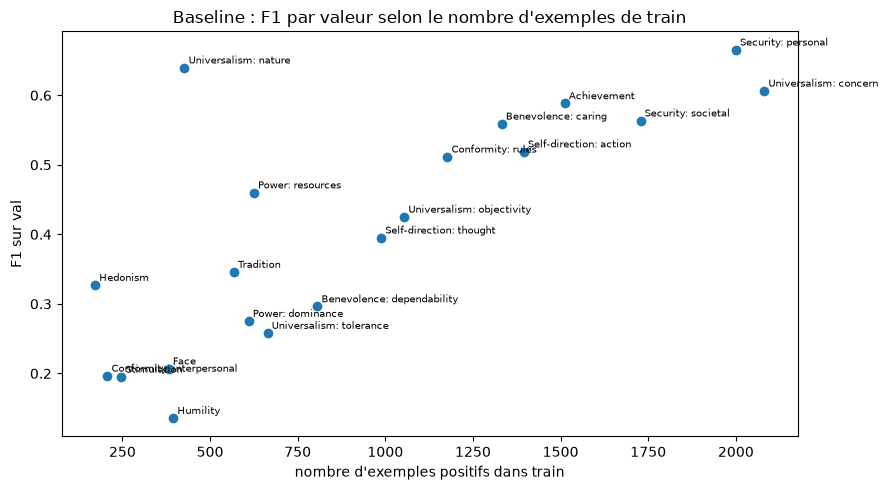

,n_train,seuil,F1 baseline,F1 « toutes valeurs »,gain
Security: personal,2000,0.47,0.665,0.572,0.094
Universalism: nature,427,0.34,0.640,0.126,0.514
Universalism: concern,2081,0.43,0.606,0.532,0.074
Achievement,1512,0.40,0.588,0.465,0.123
Security: societal,1728,0.41,0.564,0.409,0.154
Benevolence: caring,1332,0.36,0.559,0.501,0.058
Self-direction: action,1395,0.52,0.519,0.415,0.104
Conformity: rules,1177,0.42,0.512,0.387,0.125
Power: resources,625,0.39,0.460,0.130,0.330
Universalism: objectivity,1054,0.50,0.425,0.327,0.098


In [10]:
f1v = pd.DataFrame({"n_train": d["train"][VALUES].sum(), "seuil": s_valeur,
                    "F1 baseline": pd.Series(f1_par_valeur(y_va, p_va >= s_valeur)),
                    "F1 « toutes valeurs »": pd.Series(f1_par_valeur(y_va, np.ones_like(y_va)))})
f1v["gain"] = f1v["F1 baseline"] - f1v["F1 « toutes valeurs »"]
f1v = f1v.sort_values("F1 baseline", ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(f1v.n_train, f1v["F1 baseline"])
for nom, l in f1v.iterrows():
    ax.annotate(nom, (l.n_train, l["F1 baseline"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set(xlabel="nombre d'exemples positifs dans train", ylabel="F1 sur val",
       title="Baseline : F1 par valeur selon le nombre d'exemples de train")
plt.tight_layout(); plt.savefig("../figures/A_f1_vs_exemples.png", dpi=120); plt.show()
f1v.round(3)

In [11]:
log_result("baseline_tfidf_lr", "texte complet, minuscules", 0, val=scores(y_va, p_va >= s_unique),
           temps_s=round(duree, 1), params=None, notes=f"C=1, seuil unique {s_unique:.2f}")
log_result("baseline_tfidf_lr", "texte complet, minuscules", 0, val=scores(y_va, p_va >= s_valeur),
           temps_s=round(duree, 1), params=None, notes="C=1, seuil par valeur (score val optimiste)")

**Lecture :**
- La baseline atteint **macro-F1 ≈ 0,39** sur val, bien au-dessus du plancher (0,27).
- **Seuils :** passer de 0,5 à un seuil unique réglé sur val apporte +0,03. Le seuil par valeur affiche 0,409, mais en validation croisée il ne vaut que **0,390**, soit pas mieux que le seuil unique (0,394) : son gain apparent venait du réglage sur les mêmes données. **Décision pour la baseline : seuil unique 0,39.**
- **Exemples et F1 :** les valeurs fréquentes marchent mieux, mais le nombre d'exemples n'explique pas tout. *Universalism: nature* (427 exemples) atteint 0,64, tandis que *Benevolence: dependability* (806) reste à 0,30 et *Humility* (395) à 0,14. Hypothèse à vérifier en A.4 : le vocabulaire de certaines valeurs est plus concret que celui des autres.

### Le surapprentissage (overfitting), mesuré
On compare chaque modèle sur les données qu'il a vues (train) et sur celles qu'il n'a pas vues (val), au même seuil 0,5.
L'**écart** entre les deux mesure le surapprentissage.

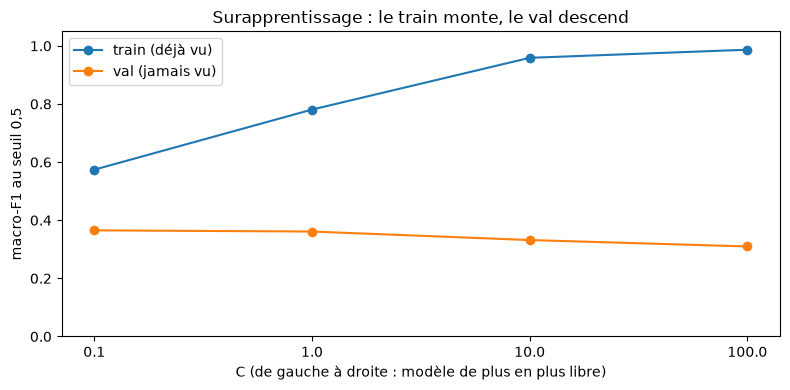

,C,macro-F1 train,macro-F1 val,écart
0,0.1,0.574,0.365,0.209
1,1.0,0.781,0.361,0.420
2,10.0,0.959,0.332,0.627
3,100.0,0.987,0.310,0.677


In [12]:
lignes = []
for C, (modele, p, _) in modeles.items():
    lignes.append({"C": C, "macro-F1 train": scores(y_tr, modele.predict_proba(X_tr) >= .5)["macro_f1"],
                   "macro-F1 val": scores(y_va, p >= .5)["macro_f1"]})
sur = pd.DataFrame(lignes)
sur["écart"] = sur["macro-F1 train"] - sur["macro-F1 val"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(len(sur)), sur["macro-F1 train"], marker="o", label="train (déjà vu)")
ax.plot(range(len(sur)), sur["macro-F1 val"], marker="o", label="val (jamais vu)")
ax.set_xticks(range(len(sur)), sur.C)
ax.set(xlabel="C (de gauche à droite : modèle de plus en plus libre)", ylabel="macro-F1 au seuil 0,5",
       ylim=(0, 1.05), title="Surapprentissage : le train monte, le val descend")
ax.legend(); plt.tight_layout(); plt.savefig("../figures/A_surapprentissage.png", dpi=120); plt.show()
sur.round(3)

### A.4 Raccourcis : que valent des règles superficielles ?

**1. Dictionnaire de mots-clés.** Pour chaque valeur, les `k` mots les plus typiques de ses arguments (log-odds), extraits du **train uniquement**. Règle : « le texte contient un de ces mots → oui ». `k` est choisi sur val.

In [13]:
from valeval.keywords import extraire, predire

lignes = []
for k in [1, 3, 10, 50, 100, 200, 300, 500]:
    s = scores(y_va, predire(d["val"], extraire(d["train"], k)))
    lignes.append({"k": k, "macro-F1": s["macro_f1"], "précision": s["macro_precision"], "rappel": s["macro_recall"]})
dico_res = pd.DataFrame(lignes)
dico_res.round(3)

,k,macro-F1,précision,rappel
0,1,0.013,0.542,0.007
1,3,0.032,0.556,0.017
2,10,0.103,0.530,0.059
3,50,0.273,0.393,0.244
4,100,0.324,0.320,0.393
5,200,0.335,0.266,0.547
6,300,0.322,0.233,0.661
7,500,0.298,0.196,0.815


In [14]:
dico10 = extraire(d["train"], 10)
pd.DataFrame({v: dico10[v] for v in ["Universalism: nature", "Hedonism", "Tradition", "Humility", "Benevolence: dependability"]})

,Universalism: nature,Hedonism,Tradition,Humility,Benevolence: dependability
0,species,fun,tradition,beauty,responsibility
1,animals,convenient,worship,plastic,responsible
2,extinct,happiness,founded,slope,hacked
3,zoos,harmless,pray,served,trusted
4,habitat,childhood,cultures,patient,required
5,pollution,meal,christian,mess,humanitarian
6,cages,recreational,centuries,changing,exam
7,conservation,treat,faith,english,lazy
8,animal,movies,prayers,changed,debts
9,environmental,daily,confusing,naturally,discipline


**2. Classifieurs à une seule règle.** Un seul mot par valeur (`k = 1`, ligne ci-dessus), et la position seule :

In [15]:
contre = (d["val"].stance == "against").to_numpy()
regle = {"Tradition": contre, "Self-direction: action": contre, "Security: personal": ~contre}
pd.DataFrame([{"règle": f"{'contre' if v != 'Security: personal' else 'pour'} → {v}",
               "F1 règle": f1_par_valeur(y_va, np.column_stack([r] * 20))[v],
               "F1 « toutes valeurs »": f1_par_valeur(y_va, np.ones_like(y_va))[v]} for v, r in regle.items()]).round(3)

,règle,F1 règle,F1 « toutes valeurs »
0,contre → Tradition,0.160,0.166
1,contre → Self-direction: action,0.507,0.415
2,pour → Security: personal,0.485,0.572


**3. Le sujet : la conclusion prédit-elle les valeurs ?** On a vu que les splits ne partagent aucun sujet. Et s'ils en partageaient ?
On mesure sur le train, en validation croisée à 5 plis, avec le même modèle :
- **sujets partagés** : découpage aléatoire, les arguments d'un même sujet sont des deux côtés ;
- **sujets séparés** : `GroupKFold`, un sujet n'est jamais des deux côtés (comme le vrai val).

In [16]:
from sklearn.model_selection import KFold

X = X_tr.reset_index(drop=True)
lignes = []
for nom, plis in [("sujets partagés", KFold(5, shuffle=True, random_state=42).split(X)),
                  ("sujets séparés", GroupKFold(5).split(X, groups=d["train"].conclusion))]:
    p = np.zeros_like(y_tr, dtype=float)
    for a, b in plis:
        p[b] = TfidfLR(C=1).fit(X.iloc[a], y_tr[a]).predict_proba(X.iloc[b])
    lignes.append({"découpage": nom, "macro-F1": scores(y_tr, p >= s_unique)["macro_f1"]})
pd.DataFrame(lignes).round(3)

,découpage,macro-F1
0,sujets partagés,0.486
1,sujets séparés,0.380


**4. Le modèle utilise-t-il ce raccourci ?** On regarde les mots de plus fort poids de la baseline, puis on la réentraîne **sans la conclusion** (ablation).

In [17]:
noms = np.array(m.mots.get_feature_names_out())
pd.DataFrame({v: noms[np.argsort(-m.clf.estimators_[VALUES.index(v)].coef_[0][:len(noms)])[:10]]
              for v in ["Universalism: nature", "Tradition", "Humility", "Benevolence: dependability"]})

,Universalism: nature,Tradition,Humility,Benevolence: dependability
0,animals,parades in,surgery in,loans against
1,zoos,language against,of cosmetic,minors in
2,whaling in,atheism against,minors in,surgery in
3,farming in,scientology against,cloning in,responsibility
4,abolish zoos,god,language against,wrong
5,whaling,cloning in,god,because people
6,climate,prayer against,selection against,good way
7,species,selection against,is,so
8,selection against,whaling against,why,responsible
9,nature,against,research against,voting in


In [18]:
entrees = {
    "conclusion + position + prémisse": texte_complet,
    "position + prémisse": lambda df: df.stance + " . " + df.premise,
    "prémisse seule": lambda df: df.premise,
}
lignes, preds = [], {}
for nom, f in entrees.items():
    p = TfidfLR(C=1).fit(f(d["train"]), y_tr).predict_proba(f(d["val"]))
    s = seuil_unique(y_va, p)
    preds[nom] = p >= s
    lignes.append({"entrée": nom, "seuil": round(s, 2), "macro-F1 val": scores(y_va, p >= s)["macro_f1"]})
    log_result("baseline_tfidf_lr", nom, 0, val=scores(y_va, p >= s), notes=f"ablation entrée, C=1, seuil {s:.2f}")
pd.DataFrame(lignes).round(3)

,entrée,seuil,macro-F1 val
0,conclusion + position + prémisse,0.39,0.394
1,position + prémisse,0.39,0.400
2,prémisse seule,0.38,0.401


**L'écart entre ces entrées est-il réel ?** On rééchantillonne val 1 000 fois (*bootstrap*) et on regarde l'écart de macro-F1 à chaque tirage. Si l'intervalle à 95 % contient 0, on ne peut pas conclure à une vraie différence.

In [19]:
rng = np.random.default_rng(42)
a, b = preds["prémisse seule"], preds["conclusion + position + prémisse"]
ecarts = []
for _ in range(1000):
    i = rng.integers(0, len(y_va), len(y_va))
    ecarts.append(scores(y_va[i], a[i])["macro_f1"] - scores(y_va[i], b[i])["macro_f1"])
print(f"prémisse seule - texte complet : {np.mean(ecarts):+.3f}, IC 95 % [{np.percentile(ecarts, 2.5):+.3f} ; {np.percentile(ecarts, 97.5):+.3f}]")

prémisse seule - texte complet : +0.006, IC 95 % [-0.002 ; +0.014]


**Lecture (Q2) :**
- **Dictionnaire :** meilleur `k` sur val = 200, macro-F1 **0,334** (précision 0,27, rappel 0,55). Au-dessus du plancher (0,27), en dessous de la baseline (0,394) : des mots-clés aident, sans suffire.
- **Règles uniques :** un seul mot par valeur : 0,013 (très peu d'arguments le contiennent). « contre → Tradition » : 0,160, moins bien que « toujours oui » (0,166), malgré l'écart observé en A.1. Aucune règle unique ne suffit.
- **Vocabulaire :** l'hypothèse de A.3 est appuyée : *Universalism: nature* a des mots concrets et cohérents (species, animals, habitat, pollution), *Humility* des mots sans lien clair (beauty, plastic, mess).
- **Sujet :** si les sujets étaient partagés, le macro-F1 passerait de **0,380 à 0,486** (+0,106). Ce gain serait artificiel. La séparation des sujets du jeu de données protège donc la validité de nos scores.
- **La baseline utilise ce raccourci** (« surgery in », « language against » : fin de conclusion + position), mais il ne se transfère pas à val : retirer la conclusion ne fait pas baisser le score (écart +0,006, IC 95 % [-0,002 ; +0,014]). La position n'apporte pas non plus de gain mesurable à ce modèle (0,400 vs 0,401).
- **Décision :** on garde l'entrée complète pour la baseline : aucun écart démontré, et c'est l'entrée imposée pour les modèles suivants. Baseline retenue : **C = 1, seuil unique 0,39, macro-F1 val 0,394**.